In [1]:
import ot
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import math
import scipy
from scipy.spatial import cKDTree
from scipy import integrate
from scipy import interpolate
from scipy.spatial import Delaunay
from scipy.spatial import Voronoi
from itertools import product
import torch
torch.manual_seed(100000)
import torch.nn as nn
import torch.optim as optim

np.random.seed(100000)  # NEW: keep the noisy data and sampled indices fixed

In [2]:
# settings
start = np.array((0., 1., 1.05))
dt = 0.01
slope = 0.1  # FIXED weighting parameter (epsilon = 1/slope = 10)
traj_length = int(1e7)
noise_level = 0.5
sample_size = int(500)
epsilon = 1e-4  # original teleportation parameter (not the weighting epsilon)
sampling_time = 1
simulation_t = int(2e4)
steps = 5
N_iters = 10000

# NEW: ablation settings -- vary the number of cells
mesh_shapes = {
    8:   (2, 2, 2),
    12:  (2, 2, 3),
    20:  (2, 2, 5),
    30:  (2, 3, 5),
    45:  (3, 3, 5),
    60:  (3, 4, 5),
    80:  (4, 4, 5),
    100: (4, 5, 5),
}
subset_sizes = list(mesh_shapes.keys())
n_trials = 10
invert_variables = [0]  # Hybrid model; use [0, 1, 2] to learn all derivatives.
ot_max_iter = 1000000

In [3]:
subset_sizes

[8, 12, 20, 30, 45, 60, 80, 100]

In [4]:
def Lorenz(x):
    x = x.T
    return np.array((10 * (x[1] - x[0]),
                     x[0] * (28 - x[2]) - x[1],
                     x[0] * x[1] - (8/3) * x[2])).T


def Lorenz_vec(x):
    return torch.stack((10 * (x[:, 1] - x[:, 0]),
                        x[:, 0] * (28 - x[:, 2]) - x[:, 1],
                        x[:, 0] * x[:, 1] - (8/3) * x[:, 2]), dim=1)


def traj(length, starts=start, model=Lorenz):
    x = starts
    values = np.zeros((length, len(starts)))
    values[0] = x
    for i in range(length - 1):
        x = x + dt * model(x)
        values[i + 1] = x
    return values


def invariant_measure(matrix):
    N = len(matrix)
    rhs = matrix.new_full((N,), epsilon / N)
    identity = torch.eye(N, dtype=matrix.dtype, device=matrix.device)
    return torch.linalg.solve(identity - (1 - epsilon) * matrix, rhs)


# def w(xs):
#     dists = torch.cdist(xs, Voronoi_centers)
#     if not torch.isfinite(dists).all():
#         raise ValueError("Nonfinite states encountered while computing cell weights.")
#     weights = torch.relu(1 - slope * dists)
#     mass = weights.sum(dim=1, keepdim=True)
#     nearest = nn.functional.one_hot(dists.argmin(dim=1), subset_size).to(weights)
#     denominator = torch.where(mass > 0, mass, torch.ones_like(mass))
#     return torch.where(mass > 0, weights / denominator, nearest)
def w(xs):
    dists = torch.cdist(xs, Voronoi_centers)
    if not torch.isfinite(dists).all():
        raise ValueError("Nonfinite states encountered while computing cell weights.")
    weights = torch.relu(1 - slope * dists)
    mass = weights.sum(dim=1, keepdim=True)
    nearest = nn.functional.one_hot(dists.argmin(dim=1), len(Voronoi_centers)).to(weights)
    denominator = torch.where(mass > 0, mass, torch.ones_like(mass))
    return torch.where(mass > 0, weights / denominator, nearest)

def Ulam(points, Tpoints):
    with torch.no_grad():
        indices = torch.as_tensor(tree.query(points.detach().cpu().numpy())[1],
                                  dtype=torch.long, device=points.device)
    weights = w(Tpoints).to(torch.float64)
    # Empty source cells were removed from Voronoi_centers before training.
    # This removes their corresponding destination cells as well.
    n_cells = len(Voronoi_centers)
    mat = weights.new_zeros((n_cells, n_cells))
    mat.index_add_(0, indices, weights)
    mass = mat.sum(dim=1, keepdim=True)
    return (mat / mass).T 
# def Ulam(points, Tpoints):
#     with torch.no_grad():
#         indices = torch.as_tensor(tree.query(points.detach().cpu().numpy())[1],
#                                   dtype=torch.long, device=points.device)
#     weights = w(Tpoints).to(torch.float64)
#     mat = weights.new_zeros((subset_size, subset_size))#Initialize the transition matrix
#     mat.index_add_(0, indices, weights)#add weights to corresponding rows
#     mass = mat.sum(dim=1, keepdim=True)
#     keep = mass.squeeze(1) > 0

#     mat = mat[keep]# Delete zero rows
#     #print(mat)
#     mat = mat / mass[keep]  # Normalize remaining rows
    
#     return mat.T


class W2Loss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, im_net):

        a = np.asarray(im_true_np, dtype=np.float64)
        b = im_net.detach().cpu().numpy().astype(np.float64)
        total_a, total = a.sum(), b.sum()
        a = a / total_a
        b = b / total
        _, log = ot.emd(a, b, MEASURE_OT_COST, log=True)

        # Dual potentials differentiate the cost with respect to normalized b.
        # Apply the chain rule through b = im_net / im_net.sum().
        dual = log["v"]
        gradient = (dual - np.dot(dual, b)) / total
        ctx.save_for_backward(torch.as_tensor(
            gradient, dtype=im_net.dtype, device=im_net.device
        ))
        return im_net.new_tensor(log["cost"])

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient

In [5]:
# Generate data and the fixed partitions (one pair per cell number) once for all trials.
trajectory_clean = traj(traj_length)
trajectory = trajectory_clean + np.random.normal(0, noise_level, (traj_length, 3))
trajectory = trajectory[int(1e4):]
del trajectory_clean

# Every sampled source must have a valid steps-ahead target.
rand_idxs = np.random.choice(len(trajectory) - steps, size=sample_size, replace=False)
randpts = torch.tensor(trajectory[rand_idxs], dtype=torch.float)
Trandpts = torch.tensor(trajectory[rand_idxs + steps], dtype=torch.float)
M_scale = torch.max(torch.abs(randpts))
randpts /= M_scale
Trandpts /= M_scale

low, high = randpts.numpy().min(axis=0), randpts.numpy().max(axis=0)

def build_meshes(n_cells):
    shape = mesh_shapes[n_cells]
    assert np.prod(shape) == n_cells
    adaptive_centers = MiniBatchKMeans(n_clusters=n_cells).fit(randpts).cluster_centers_
    axes = [low[i] + (np.arange(n) + 0.5) * (high[i] - low[i]) / n
            for i, n in enumerate(shape)]
    uniform_centers = np.array(list(product(*axes)), dtype=np.float32)
    out = {}
    for method, centers in [('adaptive', adaptive_centers), ('uniform', uniform_centers)]:
        source_ids = cKDTree(centers).query(randpts.detach().cpu().numpy())[1]
        occupied = np.bincount(source_ids, minlength=len(centers)) > 0
        out[method] = centers[occupied]
        print(f"cells = {n_cells:3d} | {method}: retained {occupied.sum()} of {len(centers)} occupied cells")
    return out

meshes = {n: build_meshes(n) for n in subset_sizes}  # meshes[n_cells][method]
scale = M_scale.item()
GT = traj(simulation_t, scale * randpts[0].numpy())
GTpts = torch.tensor(GT[:-steps] / scale, dtype=torch.float)
GTTpts = torch.tensor(GT[steps:], dtype=torch.float)  # Original units.
a = np.ones(simulation_t) / simulation_t

/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)
/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)
/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)
/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 t

cells =   8 | adaptive: retained 8 of 8 occupied cells
cells =   8 | uniform: retained 8 of 8 occupied cells
cells =  12 | adaptive: retained 12 of 12 occupied cells
cells =  12 | uniform: retained 11 of 12 occupied cells
cells =  20 | adaptive: retained 20 of 20 occupied cells
cells =  20 | uniform: retained 19 of 20 occupied cells
cells =  30 | adaptive: retained 30 of 30 occupied cells
cells =  30 | uniform: retained 22 of 30 occupied cells
cells =  45 | adaptive: retained 45 of 45 occupied cells
cells =  45 | uniform: retained 29 of 45 occupied cells
cells =  60 | adaptive: retained 60 of 60 occupied cells
cells =  60 | uniform: retained 32 of 60 occupied cells
cells =  80 | adaptive: retained 80 of 80 occupied cells
cells =  80 | uniform: retained 38 of 80 occupied cells
cells = 100 | adaptive: retained 100 of 100 occupied cells
cells = 100 | uniform: retained 43 of 100 occupied cells


/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)


In [6]:
# Reconstruction errors (W2, steps-step RMSE).
def reconstruction_error(net):
    net.eval()
    with torch.no_grad():
        x = randpts[0].clone().reshape(1, 3)
        vals = [x.cpu().numpy().flatten()]
        for _ in range(simulation_t - 1):
            V_field = Lorenz_vec(x * M_scale) / M_scale
            V_field[:, invert_variables] = net(x)[:, invert_variables]
            x = x + dt * V_field
            vals.append(x.cpu().numpy().flatten())
        vals = np.array(vals)
# Cut off trajectory before the first Inf
        invalid = np.where(~np.isfinite(vals).all(axis=1))[0]

        if len(invalid) > 0:
            cutoff = np.where(
        (np.abs(vals) > 1.5 * np.max(np.abs(GT))).any(axis=1) |
        ~np.isfinite(vals).all(axis=1)
    )[0][0]#when vals goes beyond np.max(np.abs(subGT))
            vals = vals[:cutoff]
            print(f"Trajectory diverged at step {invalid[0]}")
            subGT = GT[:len(vals)]
            a_eval = np.ones(len(vals)) / len(vals)
        else:
            subGT = GT
            a_eval = a

        subvals = M_scale.item() * vals
        M = ot.dist(subGT, subvals, metric="sqeuclidean")
        costW2, log = ot.emd2(a_eval, a_eval, M, log=True, numItermax=ot_max_iter)
        del M
        costW = float(np.sqrt(costW2))

        netpts = GTpts.clone()
        for _ in range(steps):
            Vf = Lorenz_vec(netpts * M_scale) / M_scale
            Vf[:, invert_variables] = net(netpts)[:, invert_variables]
            netpts = netpts + dt * Vf
        costL = torch.sqrt(torch.mean((M_scale * netpts - GTTpts) ** 2)).item()
    return costW, costL

In [ ]:
# Training: pointwise baseline, then mesh + cell-number loops for measure matching.
# slope is fixed at 1/10 (epsilon = 10) for every run.
slope = 1 / 10

def make_net():
    return nn.Sequential(
        nn.Linear(3, 100), nn.Tanh(),
        nn.Linear(100, 100), nn.Tanh(),
        nn.Linear(100, 100), nn.Tanh(),
        nn.Linear(100, 3)
    )

def rollout(net, pts):
    for _ in range(steps):
        V_field = Lorenz_vec(pts * M_scale) / M_scale
        V_field[:, invert_variables] = net(pts)[:, invert_variables]
        pts = pts + dt * V_field
    return pts

results = {
    'adaptive': {n: [] for n in subset_sizes},
    'uniform': {n: [] for n in subset_sizes},
    'pointwise': []
}

for iteration in range(n_trials):
    seed = 100000 + iteration
    # All methods and cell numbers share the same initialization within each trial.

    # Pointwise (baseline) -- does not depend on the mesh
    torch.manual_seed(seed)
    net2 = make_net()
    optimizer2 = optim.Adam(net2.parameters(), lr=1e-3)
    net2.train()
    loss2 = []

    with torch.no_grad():
        initial_L2 = torch.mean((rollout(net2, randpts.clone()) - Trandpts) ** 2).item()

    for i in range(N_iters):
        optimizer2.zero_grad()
        L2 = torch.mean((rollout(net2, randpts.clone()) - Trandpts) ** 2)
        if i % 500 == 0 and L2.item() < 0.05 * initial_L2:
            break
        L2.backward()
        optimizer2.step()
        loss2.append(L2.item())

    error = reconstruction_error(net2)
    results['pointwise'].append(error)
    print('trial', iteration, 'pointwise W2, RMSE:', error, flush=True)

    # Measure matching: both partition types at each cell number.
    for method in ['uniform','adaptive' ]:
        for n_cells in subset_sizes:
            centers = meshes[n_cells][method]
            Voronoi_centers = torch.tensor(centers, dtype=torch.float)
            tree = cKDTree(centers)
            centers_np = np.asarray(centers, dtype=np.float64)
            MEASURE_OT_COST = ot.dist(centers_np, centers_np, metric="sqeuclidean")

            with torch.no_grad():
                U_true = Ulam(randpts, Trandpts)
                im_true = invariant_measure(U_true)
                im_true_np = im_true.cpu().numpy()

            # Our method: match invariant measures.
            torch.manual_seed(seed)
            net1 = make_net()
            optimizer1 = optim.Adam(net1.parameters(), lr=1e-3)
            net1.train()
            loss1 = []

            with torch.no_grad():
                U_net = Ulam(randpts, rollout(net1, randpts.clone()))
                im_net = invariant_measure(U_net)
                initial_L1 = W2Loss.apply(im_net).item()

            for i in range(N_iters):
                optimizer1.zero_grad()
                U_net = Ulam(randpts, rollout(net1, randpts.clone()))
                im_net = invariant_measure(U_net)
                L1 = W2Loss.apply(im_net)
                if i % 500 == 0 and L1.item() < 0.05 * initial_L1:
                    break
                L1.backward()
                optimizer1.step()
                loss1.append(L1.item())

            error = reconstruction_error(net1)
            results[method][n_cells].append(error)
            print('trial', iteration, method, 'cells =', n_cells,
                  'W2, RMSE:', error, flush=True)


/homes/yinonghyn/.local/lib/python3.10/site-packages/ot/lp/__init__.py:576: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)


trial 0 pointwise W2, RMSE: (11.180082304701443, 0.23802165687084198)
trial 0 uniform cells = 8 W2, RMSE: (8.291783404719718, 0.79670250415802)
Trajectory diverged at step 1739
trial 0 uniform cells = 12 W2, RMSE: (512.7584961938051, 0.9368522763252258)
trial 0 uniform cells = 20 W2, RMSE: (9.379844775263852, 0.9252849817276001)
trial 0 uniform cells = 30 W2, RMSE: (2.787583597047088, 0.3475135266780853)
trial 0 uniform cells = 45 W2, RMSE: (4.720342403720185, 0.5800336003303528)
trial 0 uniform cells = 60 W2, RMSE: (2.157020495255677, 0.1411430835723877)
trial 0 uniform cells = 80 W2, RMSE: (1.9610105136692169, 0.2743505537509918)
trial 0 uniform cells = 100 W2, RMSE: (3.056281638312096, 0.40724068880081177)
trial 0 adaptive cells = 8 W2, RMSE: (2.1318959928097545, 0.1830366551876068)
trial 0 adaptive cells = 12 W2, RMSE: (2.144100643154861, 0.17811326682567596)
trial 0 adaptive cells = 20 W2, RMSE: (1.7587931225514548, 0.18101777136325836)
trial 0 adaptive cells = 30 W2, RMSE: (2.181

In [13]:
iteration

9

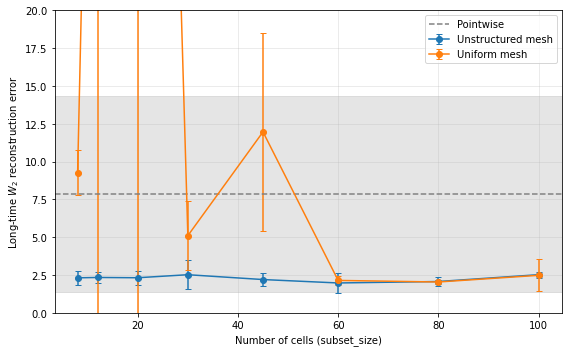

In [53]:
metric = 0
plt.figure(figsize=(8, 5))

for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [
        np.sort([r[metric] for r in results[method][n]])#[1:-1]#remove the best & worst
        for n in subset_sizes
    ]
    means = [np.mean(e) if len(e) else np.nan for e in errors]
    stds = [np.std(e) if len(e) else np.nan for e in errors]
    plt.errorbar(subset_sizes, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.sort(np.array(results['pointwise'])[:, metric])#[1:-1]#remove the best & worst
plt.axhline(baseline.mean(), color='gray', linestyle='--', label='Pointwise')
plt.axhspan(baseline.mean() - baseline.std(), baseline.mean() + baseline.std(),
            color='gray', alpha=0.2)

plt.xlabel('Number of cells (subset_size)')
plt.ylabel(r'Long-time $W_2$ reconstruction error' if metric == 0 else 'One-step RMSE')
plt.ylim(0, 20)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()

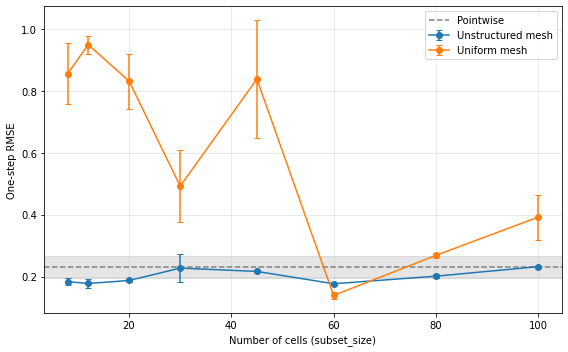

In [54]:
metric = 1
plt.figure(figsize=(8, 5))

for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [
        np.sort([r[metric] for r in results[method][n]])#[1:-1]#remove the best & worst
        for n in subset_sizes
    ]
    means = [np.mean(e) if len(e) else np.nan for e in errors]
    stds = [np.std(e) if len(e) else np.nan for e in errors]
    plt.errorbar(subset_sizes, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.sort(np.array(results['pointwise'])[:, metric])#[1:-1]#remove the best & worst
plt.axhline(baseline.mean(), color='gray', linestyle='--', label='Pointwise')
plt.axhspan(baseline.mean() - baseline.std(), baseline.mean() + baseline.std(),
            color='gray', alpha=0.2)

plt.xlabel('Number of cells (subset_size)')
plt.ylabel(r'Long-time $W_2$ reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()